En esta práctica separamos la foto de Sid en sus tres canales: rojo (R),
verde (G) y azul (B). La foto está incluida en el notebook para poder
repetir la práctica en Colab con **Entorno de ejecución → Ejecutar todas**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

La siguiente celda carga la foto incluida. Después trabajaremos con una
matriz: cada píxel tiene tres valores, en el orden rojo, verde y azul.
En esta imagen de 8 bits, cada canal toma valores entre 0 y 255.

In [2]:
# @title Cargar la foto de Sid (incluida)
import base64
from io import BytesIO

foto_base64 = "..."
imagen = Image.open(BytesIO(base64.b64decode(foto_base64))).convert("RGB")
print(f"Foto cargada: {imagen.width} × {imagen.height} píxeles.")

Foto cargada: 437 × 403 píxeles.


`[:, :, 0]` selecciona el rojo, `[:, :, 1]` el verde y `[:, :, 2]` el azul.
Los dos primeros `:` conservan todas las filas y columnas. Para ver cada
canal con su color, mantenemos sus valores y dejamos los otros dos en cero.

In [3]:
original = np.array(imagen)

R = original[:, :, 0]
G = original[:, :, 1]
B = original[:, :, 2]

rojo = np.zeros_like(original)
rojo[:, :, 0] = R

verde = np.zeros_like(original)
verde[:, :, 1] = G

azul = np.zeros_like(original)
azul[:, :, 2] = B

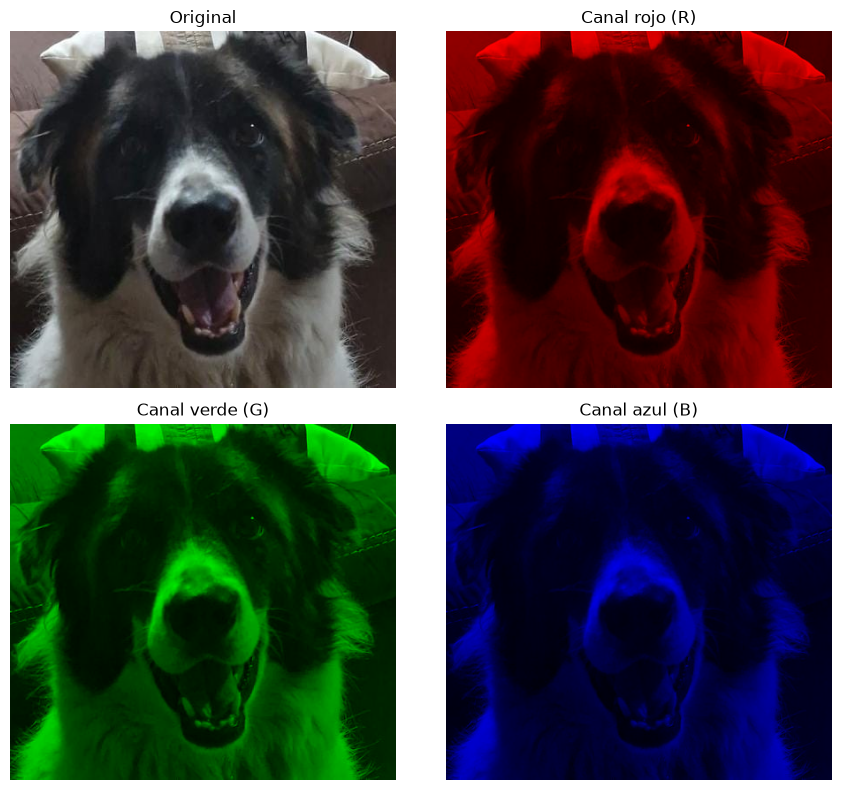

In [4]:
fig, ejes = plt.subplots(2, 2, figsize=(9, 8))
fotos = [original, rojo, verde, azul]
titulos = ['Original', 'Canal rojo (R)', 'Canal verde (G)', 'Canal azul (B)']

for eje, foto, titulo in zip(ejes.flat, fotos, titulos):
    eje.imshow(foto)
    eje.set_title(titulo)
    eje.axis('off')

plt.tight_layout()
plt.savefig('RGB_Sid.png', dpi=150)
plt.show()

Guardamos los tres canales como imágenes PNG y comprobamos que su suma
recupera exactamente la imagen original. En Colab puedes descargar las
imágenes desde el panel **Archivos**.

In [5]:
Image.fromarray(rojo).save('canal_rojo.png')
Image.fromarray(verde).save('canal_verde.png')
Image.fromarray(azul).save('canal_azul.png')

reconstruida = rojo + verde + azul
assert np.array_equal(original, reconstruida)
print('Comprobación correcta: R + G + B reproduce la imagen original.')
print('Guardados: canal_rojo.png, canal_verde.png, canal_azul.png y RGB_Sid.png.')

Comprobación correcta: R + G + B reproduce la imagen original.
Guardados: canal_rojo.png, canal_verde.png, canal_azul.png y RGB_Sid.png.


Se obtuvieron tres imágenes que conservan únicamente su componente rojo,
verde o azul. Al reunirlas recuperamos todos los colores de la foto.
Referencias: [modos y canales en Pillow](https://pillow.readthedocs.io/en/stable/handbook/concepts.html#modes)
e [indexación de matrices en NumPy](https://numpy.org/doc/stable/user/basics.indexing.html).